# Transformari neliniare ale unei distributii normale

In [3]:
import numpy as np
import matplotlib.pyplot as plt

## 1D

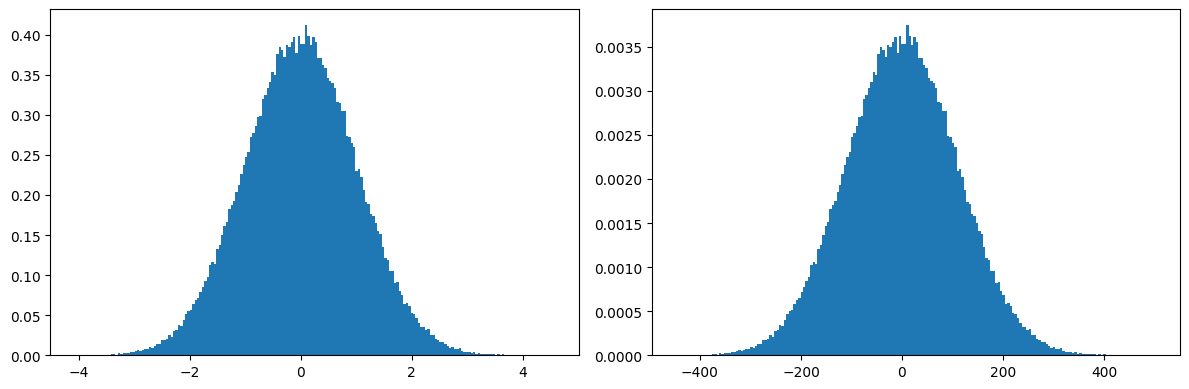

In [19]:
x_points = np.linspace(-4, 4, 1000)
normal_pdf = np.exp(-0.5 * x_points**2) / np.sqrt(2 * np.pi)

def f(x):
    return x*5

x_samples = np.random.normal(size=200_000)
y_samples = f(x_samples)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(x_samples, bins=200, density=True)
axes[1].hist(y_samples, bins=200, density=True)

plt.tight_layout()
plt.show()

## 2D


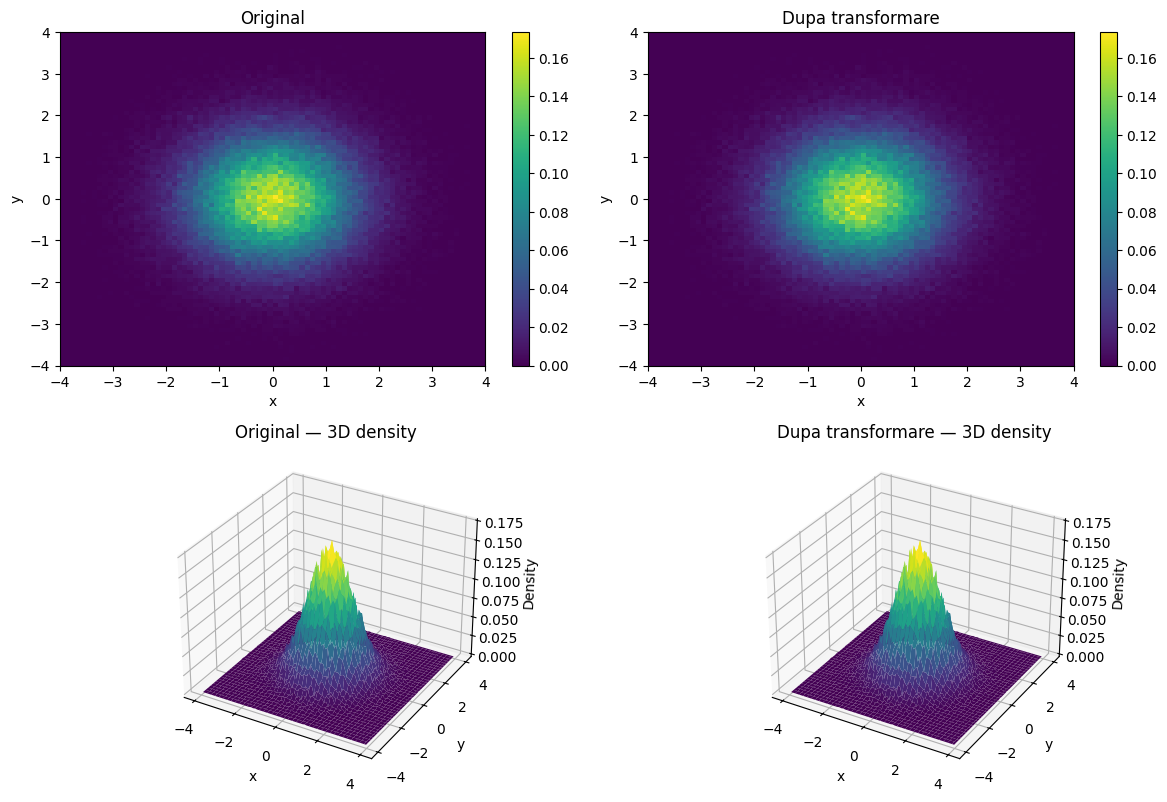

In [36]:
samples_2d = np.random.normal(size=(len(x_samples), 2))

def f_2d(samples):
    x = samples[:, 0]
    y = samples[:, 1]
    return np.column_stack((x, y))

transformed_2d = f_2d(samples_2d)

fig = plt.figure(figsize=(12, 8))

for i, (data, title) in enumerate([
    (samples_2d, "Original"),
    (transformed_2d, "Dupa transformare"),
]):
    density, x_edges, y_edges = np.histogram2d(
        data[:, 0],
        data[:, 1],
        bins=80,
        range=[[-4, 4], [-4, 4]],
        density=True,
    )

    ax = fig.add_subplot(2, 2, i + 1)
    heatmap = ax.pcolormesh(
        x_edges, y_edges, density.T
    )
    ax.set(title=title, xlabel="x", ylabel="y")
    fig.colorbar(heatmap, ax=ax)

    x_centers = (x_edges[:-1] + x_edges[1:]) / 2
    y_centers = (y_edges[:-1] + y_edges[1:]) / 2
    x_grid, y_grid = np.meshgrid(x_centers, y_centers)

    ax = fig.add_subplot(2, 2, i + 3, projection="3d")
    ax.plot_surface(x_grid, y_grid, density.T, cmap="viridis", linewidth=0)
    ax.set(title=f"{title} — 3D density", xlabel="x", ylabel="y", zlabel="Density")

plt.tight_layout()
plt.show()